# Neural networks

Companion notebook for the *Neural networks* slides. Each idea is written first by hand
with NumPy and then with the scikit-learn or SciPy tool that does the same job.

**Data:** the two moons (300 synthetic points, 2 features, 2 classes) and, for several classes,
the Digits data (1 797 images of 8 × 8 pixels, 10 digits).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import expit, softmax
from sklearn.datasets import load_digits, make_moons
from sklearn.metrics import log_loss
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

RANDOM_STATE = 42
HIDDEN_UNITS = 10
LEARNING_RATE = 0.5
STEPS = 3000
STEP_H = 1e-6

X, y = make_moons(n_samples=300, noise=0.25, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

## 1. The artificial neuron

A weighted sum plus a bias, bent by an activation: $z = \mathbf{w}^\top \mathbf{x} + b$, $a = g(z)$.
With the sigmoid $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ this is the example of the slides.

In [2]:
x_example = np.array([1, 2, -1])
w_example = np.array([0.8, 0.2, -0.5])
z = w_example @ x_example - 0.3
a_by_hand = 1 / (1 + np.exp(-z))
print(f"z = {z:.2f}, a = {a_by_hand:.3f} | same result:", np.isclose(a_by_hand, expit(z)))

z = 1.40, a = 0.802 | same result: True


## 2. The forward pass

Each layer computes $\mathbf{a}^{(l)} = g(\mathbf{W}^{(l)} \mathbf{a}^{(l-1)} + \mathbf{b}^{(l)})$, starting from $\mathbf{a}^{(0)} = \mathbf{x}$.
Here: a ReLU hidden layer and a sigmoid output. scikit-learn keeps $\mathbf{W}^{(l)}$ transposed in `coefs_`
(one row per input) and $\mathbf{b}^{(l)}$ in `intercepts_`, so a whole table of examples goes through as `A @ W + b`.

In [3]:
def forward(X: np.ndarray, W1: np.ndarray, b1: np.ndarray, W2: np.ndarray, b2: np.ndarray):
    """ReLU hidden layer, then one sigmoid output unit."""
    z1 = X @ W1 + b1
    a1 = np.maximum(0, z1)
    return z1, a1, expit(a1 @ W2 + b2).ravel()


model = MLPClassifier(hidden_layer_sizes=(HIDDEN_UNITS,), activation="relu", solver="lbfgs", max_iter=2000,
                      random_state=RANDOM_STATE).fit(X_train, y_train)
_, _, p_by_hand = forward(X_test, model.coefs_[0], model.intercepts_[0], model.coefs_[1], model.intercepts_[1])
print("same result:", np.allclose(p_by_hand, model.predict_proba(X_test)[:, 1]))
print(f"test accuracy {model.score(X_test, y_test):.3f}")

same result: True
test accuracy 0.911


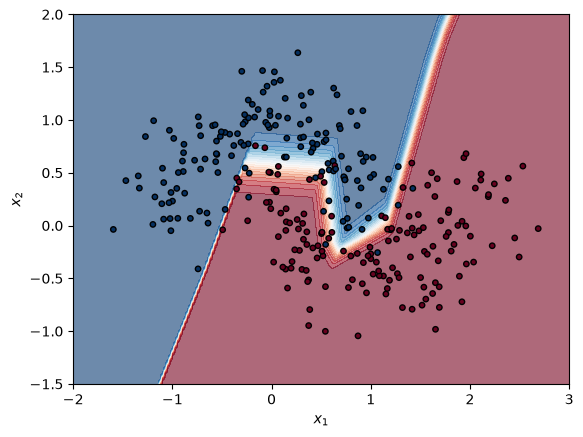

In [4]:
grid_1, grid_2 = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
p_grid = model.predict_proba(np.column_stack([grid_1.ravel(), grid_2.ravel()]))[:, 1]
plt.contourf(grid_1, grid_2, p_grid.reshape(grid_1.shape), levels=20, cmap="RdBu_r", alpha=0.6)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu_r", edgecolor="k", s=15)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.show()

## 3. Softmax output for several classes

For $K$ classes the last layer turns $K$ scores into probabilities: $\hat{y}_k = \dfrac{e^{z_k}}{\sum_{j} e^{z_j}}$.

In [5]:
X_digits, y_digits = load_digits(return_X_y=True)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_digits / 16, y_digits, test_size=0.3,
                                                        random_state=RANDOM_STATE, stratify=y_digits)
digits_model = MLPClassifier(hidden_layer_sizes=(32,), max_iter=1000, random_state=RANDOM_STATE).fit(Xd_train, yd_train)

hidden = np.maximum(0, Xd_test @ digits_model.coefs_[0] + digits_model.intercepts_[0])
scores = hidden @ digits_model.coefs_[1] + digits_model.intercepts_[1]
probs_by_hand = np.exp(scores) / np.exp(scores).sum(axis=1, keepdims=True)
print("same as scipy softmax:", np.allclose(probs_by_hand, softmax(scores, axis=1)))
print("same as predict_proba:", np.allclose(probs_by_hand, digits_model.predict_proba(Xd_test)))

same as scipy softmax: True
same as predict_proba: True


## 4. Cost and backpropagation

The cost is the mean cross-entropy $J = -\frac{1}{n}\sum_i \big[y_i \log \hat{y}_i + (1 - y_i)\log(1 - \hat{y}_i)\big]$.
Backpropagation starts from $\boldsymbol{\delta}^{(L)} = \hat{\mathbf{y}} - \mathbf{y}$, sends it back with
$\boldsymbol{\delta}^{(l)} = (\mathbf{W}^{(l+1)})^\top \boldsymbol{\delta}^{(l+1)} \odot g'(\mathbf{z}^{(l)})$,
and each gradient is $\boldsymbol{\delta}^{(l)} (\mathbf{a}^{(l-1)})^\top$.
The weights start small and random, about $1/\sqrt{n_{\text{in}}}$; a finite difference
$\big(J(\theta + h) - J(\theta - h)\big) / 2h$ on every weight checks the gradient there.

In [6]:
def cost(X: np.ndarray, y: np.ndarray, W1, b1, W2, b2) -> float:
    """Mean cross-entropy of the network."""
    p = forward(X, W1, b1, W2, b2)[2]
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


def gradients(X: np.ndarray, y: np.ndarray, W1, b1, W2, b2):
    """Backpropagation: the gradient of the cost for every weight and bias."""
    z1, a1, p = forward(X, W1, b1, W2, b2)
    delta2 = (p - y)[:, None] / len(y)
    delta1 = delta2 @ W2.T * (z1 > 0)
    return X.T @ delta1, delta1.sum(axis=0), a1.T @ delta2, delta2.sum(axis=0)


rng = np.random.default_rng(RANDOM_STATE)
params = [rng.normal(0, 1 / np.sqrt(2), (2, HIDDEN_UNITS)), np.zeros(HIDDEN_UNITS),
          rng.normal(0, 1 / np.sqrt(HIDDEN_UNITS), (HIDDEN_UNITS, 1)), np.zeros(1)]
p_train = forward(X_train, *params)[2]
print("same cost as log_loss:", np.isclose(cost(X_train, y_train, *params), log_loss(y_train, p_train)))

same cost as log_loss: True


In [7]:
def finite_differences(X: np.ndarray, y: np.ndarray, params: list) -> list:
    """Nudge each weight up and down by STEP_H and measure the change of the cost."""
    estimates = []
    for position, array in enumerate(params):
        estimate = np.zeros_like(array)
        for index in np.ndindex(array.shape):
            up, down = [p.copy() for p in params], [p.copy() for p in params]
            up[position][index] += STEP_H
            down[position][index] -= STEP_H
            estimate[index] = (cost(X, y, *up) - cost(X, y, *down)) / (2 * STEP_H)
        estimates.append(estimate)
    return estimates


backprop = gradients(X_train, y_train, *params)
numeric = finite_differences(X_train, y_train, params)
print("same result:", all(np.allclose(g, n, atol=1e-6) for g, n in zip(backprop, numeric)))

same result: True


## 5. Gradient descent by hand

From the random start, each step moves every parameter downhill: $\boldsymbol{\theta} \leftarrow \boldsymbol{\theta} - \alpha \, \nabla_{\boldsymbol{\theta}} J$.

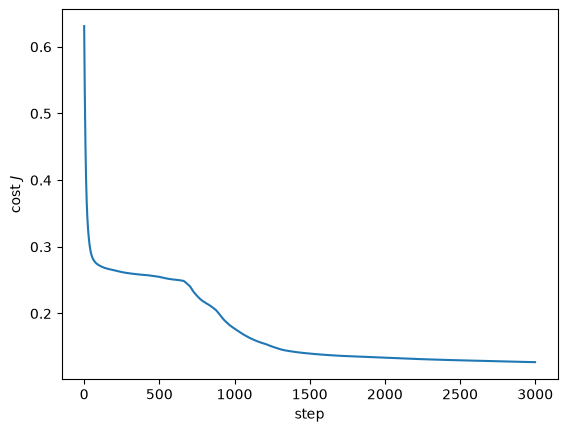

In [8]:
costs = []
for _ in range(STEPS):
    costs.append(cost(X_train, y_train, *params))
    params = [p - LEARNING_RATE * g for p, g in zip(params, gradients(X_train, y_train, *params))]

plt.plot(costs)
plt.xlabel("step")
plt.ylabel("cost $J$")
plt.show()

In [9]:
predictions_by_hand = (forward(X_test, *params)[2] >= 0.5).astype(int)
print(f"test accuracy: by hand {np.mean(predictions_by_hand == y_test):.3f}, scikit-learn {model.score(X_test, y_test):.3f}")
print(f"same prediction on {np.mean(predictions_by_hand == model.predict(X_test)):.0%} of the test points")

test accuracy: by hand 0.944, scikit-learn 0.911
same prediction on 97% of the test points


The two networks start from different random weights and scikit-learn uses another optimizer (L-BFGS)
plus a small weight penalty, so their weights differ even when their predictions mostly agree.

## Exercises

1. Build the XOR network of the slides with step activations and check its output on the four inputs.
2. Change `HIDDEN_UNITS` to 2 and to 50 in section 5. How do the cost curve and the test accuracy change?
3. Replace ReLU by tanh in `forward` and `gradients` ($\tanh' = 1 - \tanh^2$) and run the finite-difference check again.